# 04. Descriptive analyses and figures

This notebook creates the descriptive table, rank-based sensitivity analysis, and participant-level figures from the final cohort.

## Main tasks

- Create Table 1 with effect estimates and 95% confidence intervals.
- Repeat continuous comparisons with Mann–Whitney U tests.
- Report sleep as questionnaire categories rather than hours.
- Create Figs 1, 2 and 3, and save their underlying data.
- Split the high-school prevalence display at age 16 because the IDF criteria change there.

Figures are saved as 300 dpi TIFF and PNG files.


In [1]:
# Imports and paths
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

import os
# Use environment-based paths before publication; local paths are retained here.
BASE = Path(os.environ.get("METS_DATA", r"D:\eda\mets\data"))
OUT  = Path(os.environ.get("METS_OUT",  r"D:\eda\mets\output"))
for _d in (BASE, BASE/"raw", BASE/"work", OUT, OUT/"tables", OUT/"figures", OUT/"logs"):
    _d.mkdir(parents=True, exist_ok=True)
OUT_T = OUT / "tables"
OUT_F = OUT / "figures"

# Primary outcome: IDF metabolic syndrome.
TARGET = "MS"

# Journal-compatible figure size, resolution, and fonts.
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300,
    "font.family": "Arial", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
COL = {"Female": "#D55E00", "Male": "#0072B2"}

df = pd.read_csv(BASE/"work"/"Obesity_Data_proprecessing_OUTLIER.csv")
print(f"loaded {len(df):,} rows")

# Sleep is an ordinal questionnaire category, not a continuous hour value.
SLEEP_LAB = {1: "<= 6 hours", 2: ">6 to 7 hours", 3: ">7 to 8 hours", 4: ">8 hours"}
n_pos = int(df[TARGET].eq(1).sum())
print(f"MetS (IDF) {n_pos:,} ({n_pos/len(df)*100:.2f}%)  |  "
      f"reference accuracy {1-n_pos/len(df):.4f}")

def fmt_p(p):
    """Format p-values using the journal threshold at 0.001."""
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "< 0.001"
    return f"{p:.3f}"

def save_fig(fig, name):
    for ext in ("tif", "png"):
        fig.savefig(OUT_F/f"{name}.{ext}", dpi=300, bbox_inches="tight",
                    pil_kwargs={"compression": "tiff_lzw"} if ext == "tif" else None)
    print(f"  saved -> {name}.tif / .png")


loaded 13,670 rows
MetS (IDF) 1,730 (12.66%)  |  reference accuracy 0.8734


## 1. Table 1

In [2]:
# Table 1 specification: continuous, binary, categorical, and section rows.
SPEC = [
    ("__h__", "Sociodemographic", None),
    ("sex",          "Sex",                                  "cat"),
    ("age",          "Age, years",                           "cont"),
    ("global_grade", "School level",                         "cat"),

    ("__h__", "Anthropometric", None),
    ("bmi",          "Body mass index, kg/m2",               "cont"),
    ("bmi_z",        "BMI z-score",                          "cont"),

    ("__h__", "Biochemical (candidate predictors)", None),
    ("chol",         "Total cholesterol, mg/dL",             "cont"),
    ("LDL",          "LDL cholesterol, mg/dL",               "cont"),
    ("AST",          "Aspartate aminotransferase, U/L",      "cont"),
    ("ALT",          "Alanine aminotransferase, U/L",        "cont"),

    ("__h__", "Metabolic syndrome components (used to define the outcome)", None),
    ("waist",        "Waist circumference, cm",              "cont"),
    ("sysBP",        "Systolic blood pressure, mmHg",        "cont"),
    ("diaBP",        "Diastolic blood pressure, mmHg",       "cont"),
    ("HDL",          "HDL cholesterol, mg/dL",               "cont"),
    ("TG",           "Triglycerides, mg/dL",                 "cont"),
    ("glucose",      "Fasting plasma glucose, mg/dL",        "cont"),

    ("__h__", "Physical activity and weight control", None),
    ("PA",           "Physical activity (see footnote)",     "bin"),
    ("weight_control_diet",       "Weight-control dieting",    "bin"),
    ("weight_control_exercise",   "Weight-control exercise",   "bin"),
    ("weight_control_medication", "Weight-control medication", "bin"),
    ("weight_control_attempt",    "Any weight-control attempt","bin"),

    ("__h__", "Lifestyle and psychosocial", None),
    ("sleep",        "Sleep",                                   "cat"),
    ("EatingIndex",  "Eating habit index, 0-24 points",      "cont"),
    ("bully",        "Bullying victimization",               "bin"),
    ("runaway",      "Thoughts of running away from home",   "bin"),
    ("want_counseling",    "Need for counseling, school or home problems", "bin"),
    ("request_counseling", "Need for counseling, personal worries",      "bin"),
]

GRADE_LAB = {1: "4th grade, elementary (10 y)",
             2: "1st grade, middle (12-13 y)",
             3: "1st grade, high (15-16 y)"}
SEX_LABEL = {1: "Male", 0: "Female"}   # the coding used from notebook 01 on

# Editor 10 asked for effect estimates with confidence intervals rather than
# p-values alone. Standardized effects and test statistics are not reported:
# the group standard deviations differ by more than half again for four
# variables, which inflates Cohen's d for exactly those variables.
COLUMNS = ["Variable", "Non-MetS", "MetS", "Effect (95% CI)",
           "Odds ratio (95% CI)", "p"]

BLANK = {"Effect (95% CI)": "", "Odds ratio (95% CI)": "", "p": ""}


def odds_ratio_ci(table):
    """Odds ratio with a 95% Woolf interval; 0.5 is added only if a cell is 0."""
    cells = table.astype(float)
    if (cells == 0).any():
        cells = cells + 0.5
    a, b = cells[0, 0], cells[0, 1]
    c, e = cells[1, 0], cells[1, 1]
    ratio = (a * e) / (b * c)
    se = np.sqrt(1/a + 1/b + 1/c + 1/e)
    return ratio, ratio * np.exp(-1.96 * se), ratio * np.exp(1.96 * se)


def binary_effect(k_mets, n_mets, k_non, n_non):
    """Risk difference in percentage points and the odds ratio, both with CIs."""
    p_mets, p_non = k_mets / n_mets, k_non / n_non
    diff = p_mets - p_non
    se = np.sqrt(p_mets * (1 - p_mets) / n_mets + p_non * (1 - p_non) / n_non)
    table = np.array([[k_mets, n_mets - k_mets], [k_non, n_non - k_non]])
    ratio, lo, hi = odds_ratio_ci(table)
    return (f"{diff*100:+.1f} ({(diff-1.96*se)*100:+.1f}, "
            f"{(diff+1.96*se)*100:+.1f})",
            f"{ratio:.2f} ({lo:.2f}, {hi:.2f})")


def row_cont(v, label, a, b):
    ma, mb = a[v].mean(), b[v].mean()
    sa, sb = a[v].std(ddof=1), b[v].std(ddof=1)
    na, nb = len(a), len(b)
    _, p = stats.ttest_ind(a[v], b[v], equal_var=False)
    se = np.sqrt(sa**2/na + sb**2/nb)
    # Welch-Satterthwaite degrees of freedom give the critical value.
    dfw = (sa**2/na + sb**2/nb)**2 / ((sa**2/na)**2/(na-1) + (sb**2/nb)**2/(nb-1))
    crit = stats.t.ppf(0.975, dfw)
    diff = mb - ma
    return {"Variable": label,
            "Non-MetS": f"{ma:.2f} ({sa:.2f})",
            "MetS": f"{mb:.2f} ({sb:.2f})",
            "Effect (95% CI)": f"{diff:+.2f} ({diff-crit*se:+.2f}, {diff+crit*se:+.2f})",
            "Odds ratio (95% CI)": "",
            "p": fmt_p(p)}


def row_bin(v, label, a, b):
    ka, kb = int(a[v].sum()), int(b[v].sum())
    na, nb = len(a), len(b)
    table = np.array([[kb, nb-kb], [ka, na-ka]])
    _, p, _, _ = stats.chi2_contingency(table, correction=False)
    risk_diff, odds = binary_effect(kb, nb, ka, na)
    return {"Variable": label,
            "Non-MetS": f"{ka:,} ({ka/na*100:.1f})",
            "MetS": f"{kb:,} ({kb/nb*100:.1f})",
            "Effect (95% CI)": risk_diff,
            "Odds ratio (95% CI)": odds,
            "p": fmt_p(p)}


def rows_cat(v, label, a, b):
    # Use cohort-wide levels so a level absent from one group is still shown.
    levels = sorted(df[v].dropna().unique())
    table = np.array([[int((b[v] == k).sum()) for k in levels],
                      [int((a[v] == k).sum()) for k in levels]])
    _, p, _, _ = stats.chi2_contingency(table, correction=False)

    # With two categories the comparison has a single effect estimate, which
    # refers to the second category listed. With more it does not.
    if len(levels) == 2:
        kb = int((b[v] == levels[1]).sum())
        ka = int((a[v] == levels[1]).sum())
        risk_diff, odds = binary_effect(kb, len(b), ka, len(a))
    else:
        risk_diff, odds = "", ""

    head = [{"Variable": label, "Non-MetS": "", "MetS": "",
             "Effect (95% CI)": risk_diff, "Odds ratio (95% CI)": odds,
             "p": fmt_p(p)}]
    for k in levels:
        ka, kb = int((a[v] == k).sum()), int((b[v] == k).sum())
        if v == "global_grade":  name = GRADE_LAB.get(k, str(k))
        elif v == "sex":         name = SEX_LABEL.get(int(k), str(k))
        elif v == "sleep":       name = SLEEP_LAB.get(int(k), str(k))
        else:                    name = f"Category {int(k)}"
        head.append({"Variable": f"   {name}",
                     "Non-MetS": f"{ka:,} ({ka/len(a)*100:.1f})",
                     "MetS": f"{kb:,} ({kb/len(b)*100:.1f})", **BLANK})
    return head


a = df[df[TARGET] == 0]
b = df[df[TARGET] == 1]

rows = []
for v, label, kind in SPEC:
    if v == "__h__":
        rows.append({"Variable": f"\u2014 {label} \u2014", "Non-MetS": "",
                     "MetS": "", **BLANK})
    elif kind == "cont": rows.append(row_cont(v, label, a, b))
    elif kind == "bin":  rows.append(row_bin(v, label, a, b))
    else:                rows += rows_cat(v, label, a, b)

t1 = pd.DataFrame(rows)[COLUMNS]
t1.columns = ["Variable",
              f"No metabolic syndrome (n = {len(a):,})",
              f"Metabolic syndrome (n = {len(b):,})",
              "Effect (95% CI)", "Odds ratio (95% CI)", "p"]
print(t1.to_string(index=False))
t1.to_csv(OUT_T/"Table1.csv", index=False, encoding="utf-8-sig")
print("\nsaved -> tables/Table1.csv")

# C5 (Editor 10): the Results quote prevalence by sex, so write it to a file.
by_sex = (df.assign(Sex=df["sex"].map(SEX_LABEL))
            .groupby("Sex")[TARGET].agg(n="size", cases="sum", prevalence="mean"))
by_sex["cases"] = by_sex["cases"].astype(int)
by_sex["prevalence"] = (by_sex["prevalence"] * 100).round(2)
print()
print(by_sex.to_string())
by_sex.to_csv(OUT_T/"prevalence_by_sex.csv", encoding="utf-8-sig")
print("saved -> tables/prevalence_by_sex.csv")


                                                      Variable No metabolic syndrome (n = 11,940) Metabolic syndrome (n = 1,730)         Effect (95% CI) Odds ratio (95% CI)       p
                                          — Sociodemographic —                                                                                                                      
                                                           Sex                                                                         +4.8 (+2.4, +7.2)   1.23 (1.11, 1.37) < 0.001
                                                        Female                       4,641 (38.9)                     589 (34.0)                                                    
                                                          Male                       7,299 (61.1)                   1,141 (66.0)                                                    
                                                    Age, years                       14.03 (2.0

### 1b. Rank-based sensitivity analysis

In [3]:
# Median/IQR, Mann-Whitney U, and rank-biserial sensitivity analysis.
CONT = [(v, label) for v, label, kind in SPEC if kind == "cont"]

rank_rows, disagreements = [], []
for v, label in CONT:
    xa, xb = a[v].dropna(), b[v].dropna()
    u, p_u = stats.mannwhitneyu(xb, xa, alternative="two-sided")
    # Rank-biserial correlation rescales U to −1 through +1.
    rb = 2*u/(len(xa)*len(xb)) - 1
    _, p_t = stats.ttest_ind(xa, xb, equal_var=False)
    rank_rows.append({
        "Variable": label,
        "No metabolic syndrome, median (IQR)":
            f"{xa.median():.2f} ({xa.quantile(.25):.2f}-{xa.quantile(.75):.2f})",
        "Metabolic syndrome, median (IQR)":
            f"{xb.median():.2f} ({xb.quantile(.25):.2f}-{xb.quantile(.75):.2f})",
        "Rank-biserial correlation": f"{rb:+.3f}",
        "Mann-Whitney U": f"{u:,.0f}",
        "p (Mann-Whitney)": fmt_p(p_u),
        "p (Welch t-test)": fmt_p(p_t)})
    if (p_u < 0.05) != (p_t < 0.05):
        disagreements.append((label, p_t, p_u))

rank_table = pd.DataFrame(rank_rows)
print(rank_table.to_string(index=False))
rank_table.to_csv(OUT_T/"rank_based_sensitivity.csv", index=False, encoding="utf-8-sig")
print(f"\nsaved -> tables/rank_based_sensitivity.csv")

if disagreements:
    print("\nThe two tests disagree at the 0.05 level for:")
    for label, p_t, p_u in disagreements:
        print(f"  {label}: Welch p = {p_t:.4f}, Mann-Whitney p = {p_u:.4f}")
    print("The sentence in the Results must name these variables.")
else:
    print("\nEvery continuous variable reaches the same conclusion under both tests.")


                       Variable No metabolic syndrome, median (IQR) Metabolic syndrome, median (IQR) Rank-biserial correlation Mann-Whitney U p (Mann-Whitney) p (Welch t-test)
                     Age, years                 13.42 (12.71-15.87)              15.47 (12.88-16.01)                    +0.110     11,465,560          < 0.001          < 0.001
         Body mass index, kg/m2                 27.59 (26.22-29.74)              29.99 (27.66-32.56)                    +0.376     14,214,474          < 0.001          < 0.001
                    BMI z-score                    2.26 (1.88-2.81)                 2.83 (2.28-3.48)                    +0.378     14,237,068          < 0.001          < 0.001
       Total cholesterol, mg/dL              166.00 (148.00-186.00)           175.00 (156.00-197.00)                    +0.171     12,096,961          < 0.001          < 0.001
         LDL cholesterol, mg/dL                97.00 (81.00-115.00)             99.00 (81.00-118.00)                    

### Table 1 footnote

> Values are mean (SD) for continuous variables and n (%) for categorical
> variables. Continuous variables were compared using Welch's t-test and
> categorical variables using Pearson's chi-square test without continuity
> correction. Effect estimates are the difference in means (metabolic syndrome
> minus no metabolic syndrome) for continuous variables and the difference in
> proportions in percentage points for binary variables, each with a 95%
> confidence interval; odds ratios are given with a 95% Woolf interval. For a
> variable with two categories the effect estimate refers to the second
> category listed. For variables with more than two categories no single effect
> estimate applies, and the category proportions describe the difference.
> Statistical significance was assessed at a two-sided alpha of 0.05. Exact
> p-values are reported for values of 0.001 and above; values below that are
> shown as p < 0.001.
>
> Table 1 is descriptive. No adjustment for multiple comparisons was made and no
> confirmatory hypothesis was tested; effect estimates with confidence intervals
> are reported so that interpretation does not rest on statistical significance
> alone. A rank-based sensitivity analysis of all continuous variables is given
> in the rank-based sensitivity table published with the code.
>
> **Physical activity** was harmonized across school levels from two
> questionnaire items about exercise vigorous enough to cause shortness of
> breath or sweating. Elementary-school students were asked whether they
> exercised this way at least three times per week. Middle- and high-school
> students reported the number of days per week with 30 minutes to 1 hour or
> more of such exercise; responses of 3–4 days and 5 days or more were coded as
> meeting the criterion. Both items therefore identify vigorous activity on at
> least three days per week, although only the secondary-school item specifies
> duration.
>
> **Sleep** is recorded as an ordered questionnaire category rather
> than a continuous number of hours. The response options are (1) 6 hours or
> less, (2) more than 6 to 7 hours, (3) more than 7 to 8 hours, and (4) more
> than 8 hours. The first and last bands are open-ended, so no midpoint or
> continuous sleep-hour value is derived. The models use the ordered response
> code.
>
> Metabolic syndrome components are listed separately because they were used to
> define the outcome and were not entered as predictors in the models.


## 2. Fig 2: metabolic syndrome prevalence by school level, age band and sex

  saved -> Fig2_mets_prevalence_by_group_and_sex.tif / .png


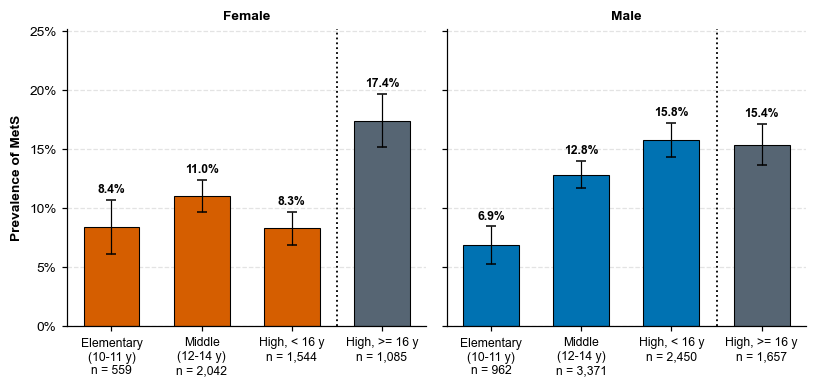

   Sex       Group  size   sum   mean     se
Female  Elementary   559  47.0 0.0841 0.0117
Female High 10-<16  1544 128.0 0.0829 0.0070
Female   High >=16  1085 189.0 0.1742 0.0115
Female      Middle  2042 225.0 0.1102 0.0069
  Male  Elementary   962  66.0 0.0686 0.0082
  Male High 10-<16  2450 387.0 0.1580 0.0074
  Male   High >=16  1657 255.0 0.1539 0.0089
  Male      Middle  3371 433.0 0.1284 0.0058


In [4]:
# Split high school at age 16 to avoid mixing IDF pediatric and adult criteria.
SEXL, GRADL = {1: "Male", 0: "Female"}, {1: "Elementary", 2: "Middle", 3: "High"}
d = df.assign(Sex=df["sex"].map(SEXL), Grade=df["global_grade"].map(GRADL))
d["Group"] = d["Grade"]
is_high = d["Grade"] == "High"
d.loc[is_high, "Group"] = "High " + d.loc[is_high, "age_band"]

order = ["Elementary", "Middle", "High 10-<16", "High >=16"]
xlabels = ["Elementary\n(10-11 y)", "Middle\n(12-14 y)",
           "High, < 16 y", "High, >= 16 y"]

summ = d.groupby(["Sex", "Group"])[TARGET].agg(["size", "sum", "mean"]).reset_index()
summ["se"] = np.sqrt(summ["mean"]*(1-summ["mean"])/summ["size"])

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.6), sharey=True)
for ax, sx in zip(axes, ["Female", "Male"]):
    s = summ[summ.Sex == sx].set_index("Group").loc[order]
    x = np.arange(len(order))
    # The 16-years-and-older band uses the adult criteria, so it is drawn
    # in a darker grey that holds its own against the stronger bar colours.
    colors = [COL[sx]] * 3 + ["#566573"]
    ax.bar(x, s["mean"], width=.62, color=colors, edgecolor="black", lw=.7,
           yerr=1.96*s["se"], capsize=3, error_kw={"lw": .8})
    # The percentage sits above the error bar.
    for xi, m in enumerate(s["mean"]):
        ax.text(xi, m + 1.96*s["se"].iloc[xi] + .006, f"{m*100:.1f}%",
                ha="center", fontsize=8, fontweight="bold")
    # Mark the age-16 criterion change.
    ax.axvline(2.5, color="black", ls=":", lw=1.2)
    # The group size is carried on a further line of the tick label, below
    # the axis, so that it does not have to be read against the bar colour.
    tick_labels = []
    for xi, n in enumerate(s["size"]):
        tick_labels.append(f"{xlabels[xi]}\nn = {n:,}")
    ax.set_xticks(x); ax.set_xticklabels(tick_labels, fontsize=8)
    ax.set_title(sx, fontweight="bold", fontsize=9)
    ax.grid(axis="y", ls="--", alpha=.35); ax.set_axisbelow(True)
ax.set_ylim(0, max(summ["mean"] + 1.96*summ["se"]) * 1.28)
axes[0].set_ylabel("Prevalence of MetS", fontweight="bold",
                   fontsize=9)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v*100:.0f}%")
# Titles and captions are supplied in the manuscript, not inside the image.
fig.tight_layout(); save_fig(fig, "Fig2_mets_prevalence_by_group_and_sex"); plt.show()

print(summ.round(4).to_string(index=False))
summ.to_csv(OUT_T/"Fig2_data.csv", index=False, encoding="utf-8-sig")


## 3. Fig 3: sex differences in health-related behaviors


  saved -> Fig3_sex_differences_behaviors.tif / .png


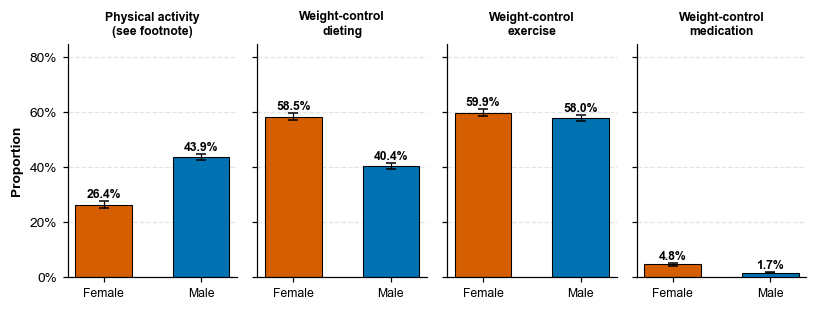

          PA                 weight_control_diet               weight_control_exercise               weight_control_medication             
        size     sum    mean                size   sum    mean                    size   sum    mean                      size  sum    mean
Sex                                                                                                                                        
Female  5230  1382.0  0.2642                5230  3060  0.5851                    5230  3135  0.5994                      5230  251  0.0480
Male    8440  3706.0  0.4391                8440  3407  0.4037                    8440  4892  0.5796                      8440  145  0.0172

saved -> tables/Fig3_data.csv

physical activity   female 26.4%   male 43.9%
metabolic syndrome  female 11.3%   male 13.5%


In [5]:
# Fig 3 in the original submission; the editor did not ask for it to change.
# The values also support the cautious reading of the sex variable that
# Editor 8 asks for. Uses the labeled data frame created in the preceding cell.
ITEMS = [("PA", "Physical activity\n(see footnote)"),
         ("weight_control_diet", "Weight-control\ndieting"),
         ("weight_control_exercise", "Weight-control\nexercise"),
         ("weight_control_medication", "Weight-control\nmedication")]

fig, axes = plt.subplots(1, len(ITEMS), figsize=(7.5, 2.9), sharey=True)
for ax, (v, lab) in zip(axes, ITEMS):
    s = d.groupby("Sex")[v].agg(["size", "mean"]).loc[["Female", "Male"]]
    se = np.sqrt(s["mean"]*(1-s["mean"])/s["size"])
    ax.bar(np.arange(2), s["mean"], width=.58,
           color=[COL["Female"], COL["Male"]], edgecolor="black", lw=.7,
           yerr=1.96*se, capsize=3, error_kw={"lw": .8})
    for i, m in enumerate(s["mean"]):
        ax.text(i, m + 1.96*se.iloc[i] + .012, f"{m*100:.1f}%",
                ha="center", fontsize=8, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Female", "Male"], fontsize=8)
    ax.set_title(lab, fontsize=8, fontweight="bold")
    ax.grid(axis="y", ls="--", alpha=.35); ax.set_axisbelow(True)
axes[0].set_ylim(0, .85)
axes[0].set_ylabel("Proportion", fontweight="bold", fontsize=9)
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v*100:.0f}%")
fig.tight_layout(); save_fig(fig, "Fig3_sex_differences_behaviors"); plt.show()

# Save the values underlying Fig 3.
fig3 = d.groupby("Sex")[[v for v, _ in ITEMS]].agg(["size", "sum", "mean"])
print(fig3.round(4).to_string())
fig3.to_csv(OUT_T/"Fig3_data.csv", encoding="utf-8-sig")
print("\nsaved -> tables/Fig3_data.csv")

# The sex difference in prevalence does not follow the physical-activity
# difference: boys are the more active group and still have the higher
# prevalence, so activity does not account for the sex signal in the model.
female = d[d["Sex"] == "Female"]
male = d[d["Sex"] == "Male"]
print()
print(f"physical activity   female {female['PA'].mean()*100:.1f}%"
      f"   male {male['PA'].mean()*100:.1f}%")
print(f"metabolic syndrome  female {female[TARGET].mean()*100:.1f}%"
      f"   male {male[TARGET].mean()*100:.1f}%")


## 4. Participant flow reconciliation

Figure 1 is drawn outside this notebook. The exclusion counts are still
joined and checked here, so that the figure and the manuscript cannot drift
apart from the numbers the pipeline actually produced.


In [6]:
# Notebooks 01, 02 and 03 each write their own segment of the exclusion log.
# Joining them here gives the counts that Figure 1 has to show.
segments = []
for name in ["flow_01.csv", "flow_02.csv", "flow_03.csv"]:
    segments.append(pd.read_csv(OUT_T/name))

flow = pd.concat(segments, ignore_index=True)
flow["step"] = np.arange(len(flow))
flow.to_csv(OUT_T/"flow.csv", index=False, encoding="utf-8-sig")

# Every record leaving the cohort must be accounted for by one exclusion step.
start = int(flow.remaining.iloc[0])
final = int(flow.remaining.iloc[-1])
if start - int(flow.excluded.sum()) != final:
    raise ValueError("the exclusion counts do not reconcile with the final n")
if final != len(df):
    raise ValueError("the flow log and the analytic file disagree on the final n")

n_steps = int((flow.excluded > 0).sum())
print(f"participant flow {start:,} -> {final:,}  ({n_steps} exclusion steps)")
print(flow.to_string(index=False))
print("\nsaved -> tables/flow.csv")


participant flow 366,903 -> 13,670  (16 exclusion steps)
 step                                                      stage  excluded  remaining  excluded_MS  excluded_MS_atp3
    0       Merged Student Health Examination records, 2021-2024         0     366903          NaN               NaN
    1                                   Missing height or weight         1     366902          NaN               NaN
    2              Invalid date, grade-age mismatch, or age <= 5       165     366737          NaN               NaN
    3                                             Age < 10 years     85064     281673          NaN               NaN
    4         MetS components not measured (no biochemical exam)    266674      14999          NaN               NaN
    5            Weight-control items: conflicting or unanswered      1009      13990          NaN               NaN
    6                           Dietary items invalid or missing         6      13984          NaN               NaN
    7  

---

## Output and submission check

- `Table1.csv`, `prevalence_by_sex.csv` and `rank_based_sensitivity.csv`
- `Fig2_mets_prevalence_by_group_and_sex.tif` and `Fig3_sex_differences_behaviors.tif`
- `flow.csv`, `Fig2_data.csv` and `Fig3_data.csv`
- Figure 1 is drawn outside this notebook from `flow.csv`

Before submission, rerun notebooks 01–05 in order, confirm that the sleep row is
reported as n (%), confirm the counseling labels against the source questionnaire,
and review any Welch/Mann–Whitney disagreement printed by this notebook.
